In [1]:
import numpy as np
from cosmoTransitions.tunneling1D import SingleFieldInstanton
import matplotlib.pyplot as plt
import pandas as pd
from scipy import optimize as optimize
import scipy.integrate as integrate
from scipy import interpolate, special


####Some definitions##
v2 = 246.**2 
mh=125
v=246
alpha=1/137 #fine structure constant
sinthw=np.sqrt(0.223) #sine of Weinberg angle
g1=np.sqrt(4*np.pi*alpha/(1-sinthw**2)) ## U(1)_Y gauge coupling constant
g=np.sqrt(4*np.pi*alpha)/sinthw #SU(2)_L gauge coupling constant
Mplanck=2.4*10**18 #reduced planck mass
mZ=np.sqrt(v**2/4*(g**2+g1**2))###Z boson mass

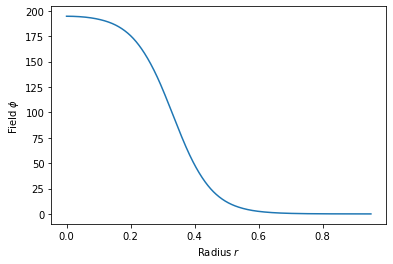

[0.00000000e+00 3.84693366e-08 4.79954196e-06 ... 4.74682787e-03
 4.75158895e-03 4.75635002e-03]


In [25]:
#Definition of the potential#
Tc = 100.
L = 0.1*Tc**4
sigma = 0.1*Tc**3
lc = 6/Tc
T0 = Tc/(1+6*sigma/(L*lc))**0.5
a = 1/(2/3*sigma*lc**5*Tc**2)**0.5
gamma = (L+6*sigma/lc)/(6*sigma*lc*Tc**2)
lam = 1/(3*sigma*lc**3)
T = 93.
def V(phi): return 0.5*gamma*(T**2-T0**2)*phi**2-1/3*a*T*phi**3+0.25*lam*phi**4
def dV(phi): return gamma*(T**2-T0**2)*phi-a*T*phi**2+lam*phi**3

#critical bubble#
xi = np.array(range(25000))*0.01
Vmin = np.amin(V(xi))
vt = xi[np.where(V(xi) == Vmin)[0]][0] ##find location of the global minimum
profile = SingleFieldInstanton(vt, 0.0, V, dV).findProfile(npoints=1000)
plt.plot(profile.R, profile.Phi)
plt.xlabel(r"Radius $r$")
plt.ylabel(r"Field $\phi$")
plt.show()
print(profile.R*dr)

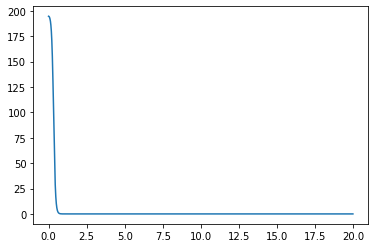

In [61]:
#initialization of the evolution#
fphi = interpolate.interp1d(profile.R, profile.Phi, fill_value=(0), bounds_error=False)
dr=0.0015
r  = np.array(range(0, int(np.floor(20/dr))))*dr
phi0 = fphi(r)
phi2 = np.zeros(r.size)
plt.plot(r,phi0)
plt.show()

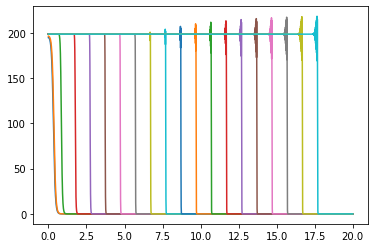

In [62]:
####Solving equation (8) of arxiv:9512202 with \eta=0
###Lattice approach:

dt = 0.001
phi=phi0
for i in range(20000):#--------------------------------------------------iterate over time
    #------1 step evolution
    phi = 0.5*dt*phi2 + phi
    lphi=np.append(phi[1:],0)
    rphi=np.append(phi[0],phi[:-1])
    #------2nd step evolution 
    dphi_dr=(lphi-rphi)/(2*dr) #----------------------------------first spatial derivative
    d2phi_dr2 = (lphi + rphi - 2 * phi)/(dr**2) #----------------------2nd spatial derivative
    phi2 = phi2 + dt*(d2phi_dr2 + 2/(r+dr)*dphi_dr - dV(phi) )
    #-------3rd step evolution
    phi = 0.5*dt*phi2 +phi
    if(i%1000==0):
        plt.plot(r,phi)

   

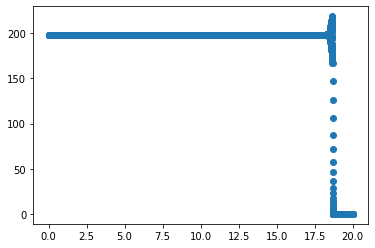

In [69]:
plt.scatter(r,phi)

In [74]:
phi_half=(max(phi0)-min(phi0))*0.5
myfun=interpolate.interp1d(r,phi)

In [83]:
np.min(abs(phi-phi_half))

8.621059595048223